# [GSE157268](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE157268)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-10-15
> - Modified: 2025-02-15

# 1. Experimental Design

> Nuclear m6A reader Ythdc1 regulates the scaffold function of LINE1 RNA in mouse ESCs and early embryos.
> - Chuan Chen, Wenqiang Liu, Jiayin Guo, Yuanyuan Liu, Xuelian Liu, Jun Liu, Xiaoyang Dou, Rongrong Le, Yixin Huang, Chong Li, Lingyue Yang, Xiaochen Kou, Yanhong Zhao, You Wu, Jiayu Chen, Hong Wang, Bin Shen, Yawei Gao, Shaorong Gao, Nuclear m6A reader YTHDC1 regulates the scaffold function of LINE1 RNA in mouse ESCs and early embryos, Protein & Cell, Volume 12, Issue 6, June 2021, Pages 455–474, https://doi.org/10.1007/s13238-021-00837-8.
> - Total RNA-seq
> - VAHTS Total RNA-seq (H/M/R) Library Prep Kit (dUTP)
> - Illumina NovaSeq 6000, PE150
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Treatment | Replicate |
| - | - | - | - | - | - | - | - |
| Wildtype | Mus musculus | mESC | Blastocyst-derived embryionic stem cells | C57BL/6 | Wild Type | Control | rep1~3 |
| Ythdc1-cKO | Mus musculus | mESC | Blastocyst-derived embryionic stem cells | C57BL/6 | Ythdc1 flox/flox | Conditional knockout ESCs **CreERT2** | rep1~3 |
| Ythdc1-W378A | Mus musculus | mESC | Blastocyst-derived embryionic stem cells | C57BL/6 | Ythdc1 flox/flox | CreERT2, rescued with an **m6A-binding-deficient YTHDC1 mutant (W378A)** | rep1~3 |
| Ythdc1-wtRes | Mus musculus | mESC | Blastocyst-derived embryionic stem cells | C57BL/6 | Ythdc1 flox/flox | CreERT2, rescued with exogenous **wild-type YTHDC1** | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Mettl3_GSE157268/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)

[1] 55335    23

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, pattern = "Wildtype|Ythdc1")) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "cKO", "wtRes", "W378A")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Wildtype,WT,rep1
WT_rep2,mESC,Wildtype,WT,rep2
WT_rep3,mESC,Wildtype,WT,rep3
cKO_rep1,mESC,Ythdc1,cKO,rep1
cKO_rep2,mESC,Ythdc1,cKO,rep2
cKO_rep3,mESC,Ythdc1,cKO,rep3
wtRes_rep1,mESC,Ythdc1,wtRes,rep1
wtRes_rep2,mESC,Ythdc1,wtRes,rep2
wtRes_rep3,mESC,Ythdc1,wtRes,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("Wildtype|Ythdc1")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "Wildtype|Ythdc1")

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = gsub(sampleName, pattern = "-", replacement = "_"), 
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("WT", "cKO", "wtRes", "W378A")), 
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Replicate
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC_Wildtype_WT_rep1.tsv,mESC,Wildtype,WT,rep1
WT_rep2,mESC_Wildtype_WT_rep2.tsv,mESC,Wildtype,WT,rep2
WT_rep3,mESC_Wildtype_WT_rep3.tsv,mESC,Wildtype,WT,rep3
cKO_rep1,mESC_Ythdc1_cKO_rep1.tsv,mESC,Ythdc1,cKO,rep1
cKO_rep2,mESC_Ythdc1_cKO_rep2.tsv,mESC,Ythdc1,cKO,rep2
cKO_rep3,mESC_Ythdc1_cKO_rep3.tsv,mESC,Ythdc1,cKO,rep3
wtRes_rep1,mESC_Ythdc1_wtRes_rep1.tsv,mESC,Ythdc1,wtRes,rep1
wtRes_rep2,mESC_Ythdc1_wtRes_rep2.tsv,mESC,Ythdc1,wtRes,rep2
wtRes_rep3,mESC_Ythdc1_wtRes_rep3.tsv,mESC,Ythdc1,wtRes,rep3


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype|Ythdc1")
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "cKO", "wtRes", "W378A")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Wildtype,WT,rep1
WT_rep2,mESC,Wildtype,WT,rep2
WT_rep3,mESC,Wildtype,WT,rep3
cKO_rep1,mESC,Ythdc1,cKO,rep1
cKO_rep2,mESC,Ythdc1,cKO,rep2
cKO_rep3,mESC,Ythdc1,cKO,rep3
wtRes_rep1,mESC,Ythdc1,wtRes,rep1
wtRes_rep2,mESC,Ythdc1,wtRes,rep2
wtRes_rep3,mESC,Ythdc1,wtRes,rep3


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype|Ythdc1")

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_[^_]+_", "", names),
        Group = factor(Group, levels = c("WT", "cKO", "wtRes", "W378A")), 
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>   
    select("names", "files", "Cell", "Gene", "Group", "Replicate") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files"))

names,Cell,Gene,Group,Replicate
<chr>,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Wildtype,WT,rep1
WT_rep2,mESC,Wildtype,WT,rep2
WT_rep3,mESC,Wildtype,WT,rep3
cKO_rep1,mESC,Ythdc1,cKO,rep1
cKO_rep2,mESC,Ythdc1,cKO,rep2
cKO_rep3,mESC,Ythdc1,cKO,rep3
wtRes_rep1,mESC,Ythdc1,wtRes,rep1
wtRes_rep2,mESC,Ythdc1,wtRes,rep2
wtRes_rep3,mESC,Ythdc1,wtRes,rep3


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-15 09:33:55

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene 

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 12 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(5): names Cell Gene Group Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype|Ythdc1")
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "cKO", "wtRes", "W378A")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Wildtype,WT,rep1
WT_rep2,mESC,Wildtype,WT,rep2
WT_rep3,mESC,Wildtype,WT,rep3
cKO_rep1,mESC,Ythdc1,cKO,rep1
cKO_rep2,mESC,Ythdc1,cKO,rep2
cKO_rep3,mESC,Ythdc1,cKO,rep3
wtRes_rep1,mESC,Ythdc1,wtRes,rep1
wtRes_rep2,mESC,Ythdc1,wtRes,rep2
wtRes_rep3,mESC,Ythdc1,wtRes,rep3


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 12 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(12): WT_rep1 WT_rep2 ... W378A_rep2 W378A_rep3
colData names(4): Cell Gene Group Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 17608 
 Remove: 37727 
 Retention rate: 31.82 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 17546 
 Remove: 37789 
 Retention rate: 31.71 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
rld <- rlog(dds, blind = FALSE)

In [32]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [33]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [34]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


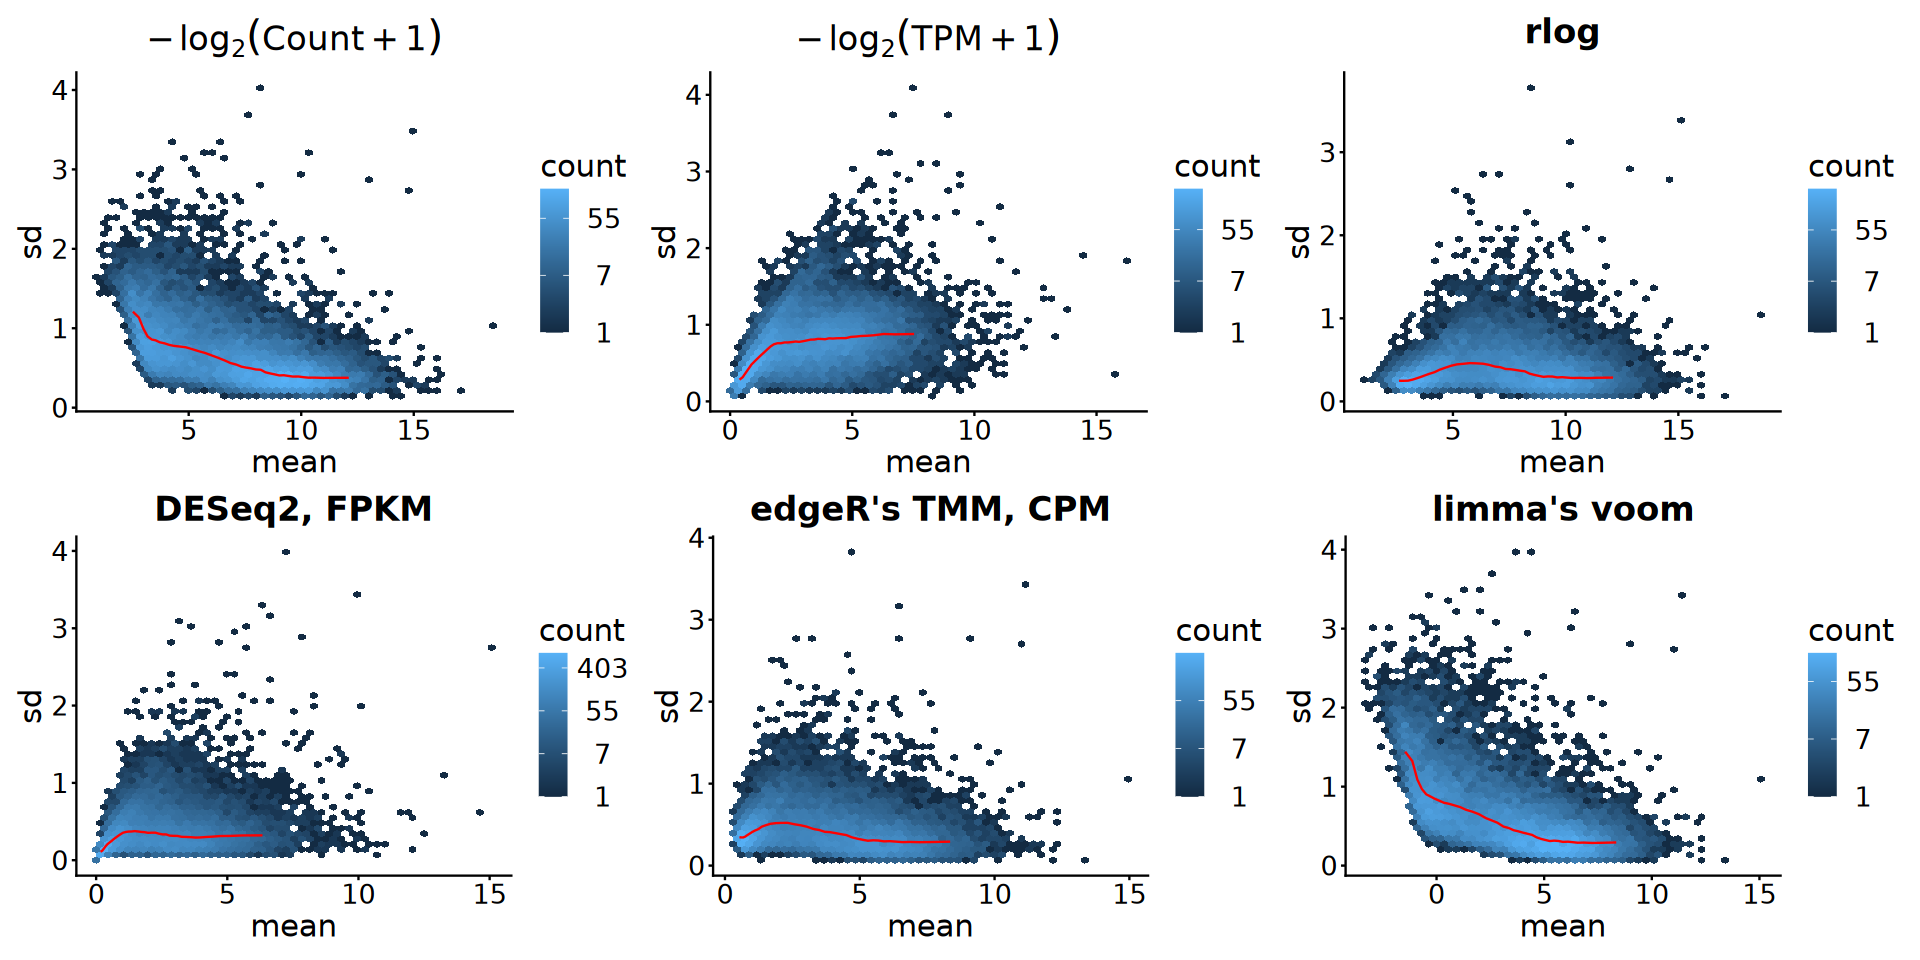

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

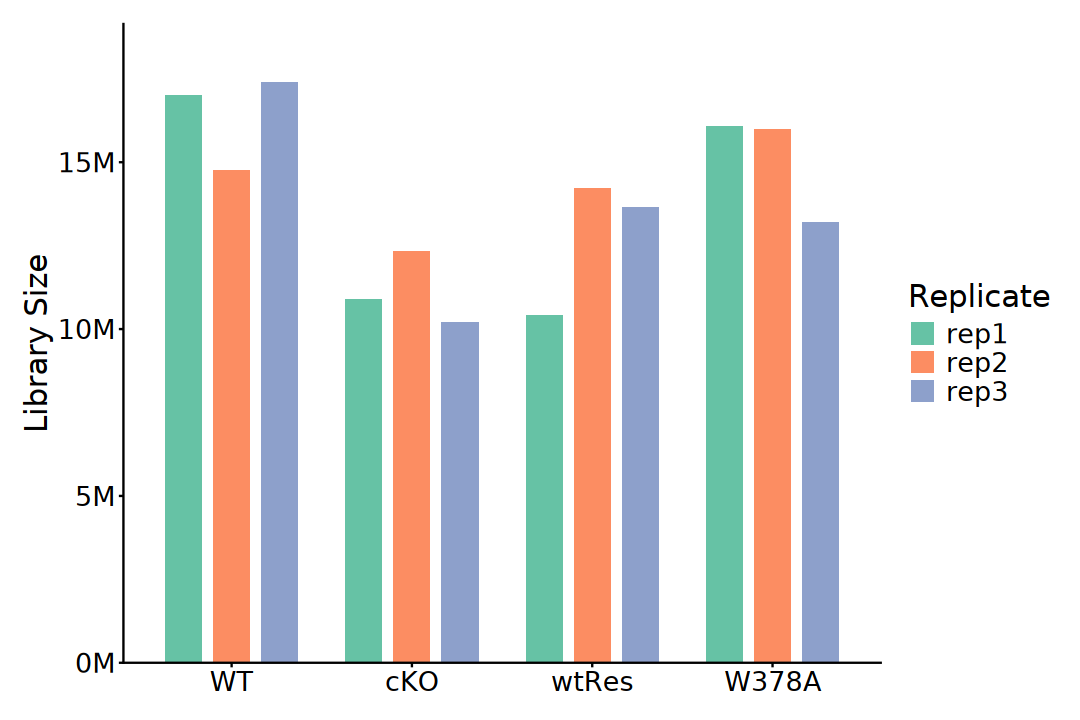

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

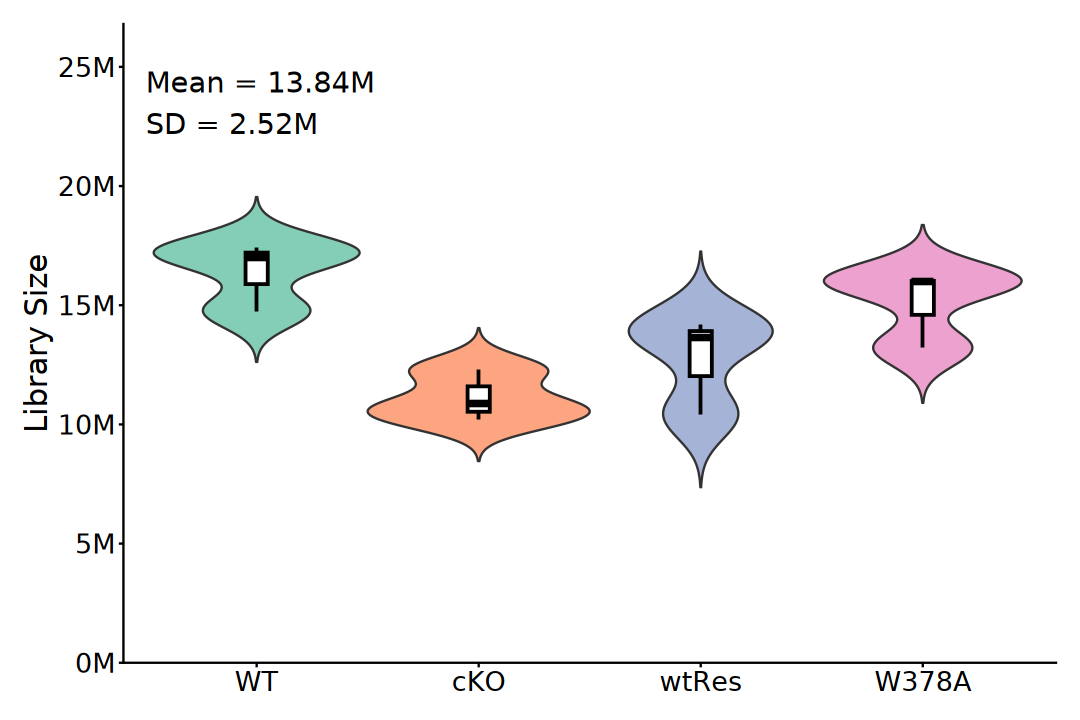

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = FALSE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.4,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.3,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [43]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [44]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [45]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [46]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [47]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

Warning message in glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2):
"Reached maximum number of iterations (1000) without numerical convergence. Results may be unreliable."


In [49]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

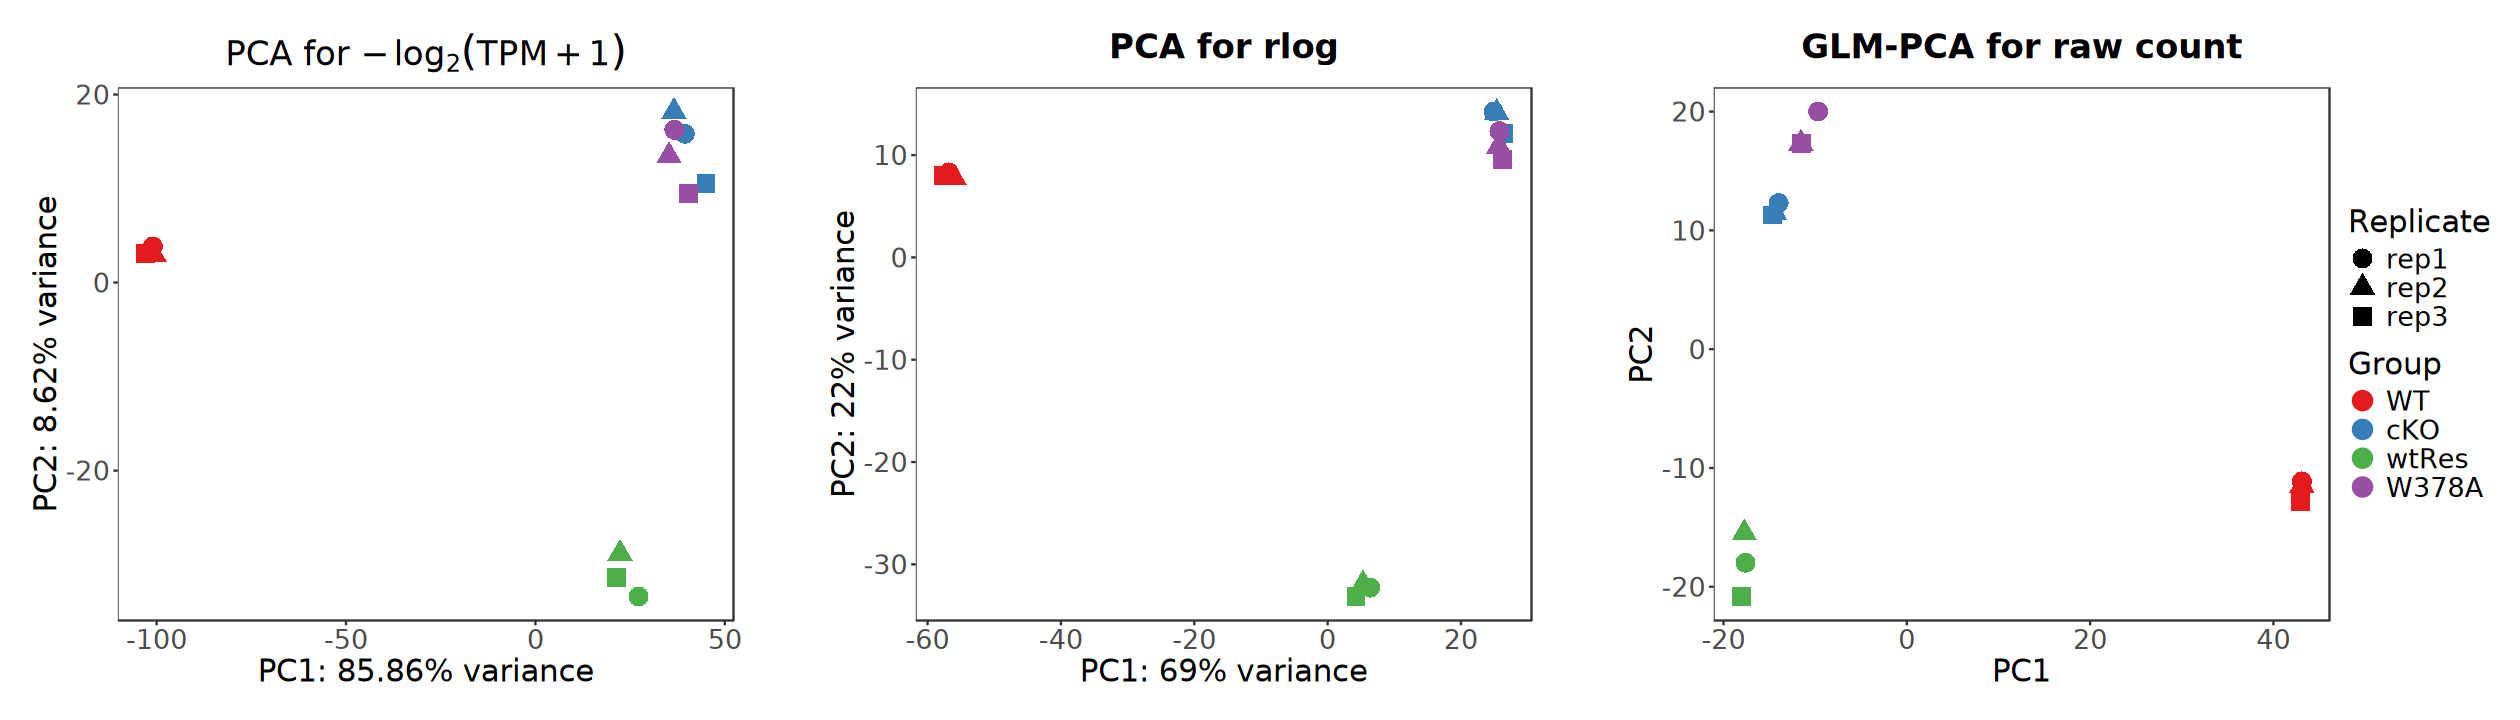

In [50]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [51]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

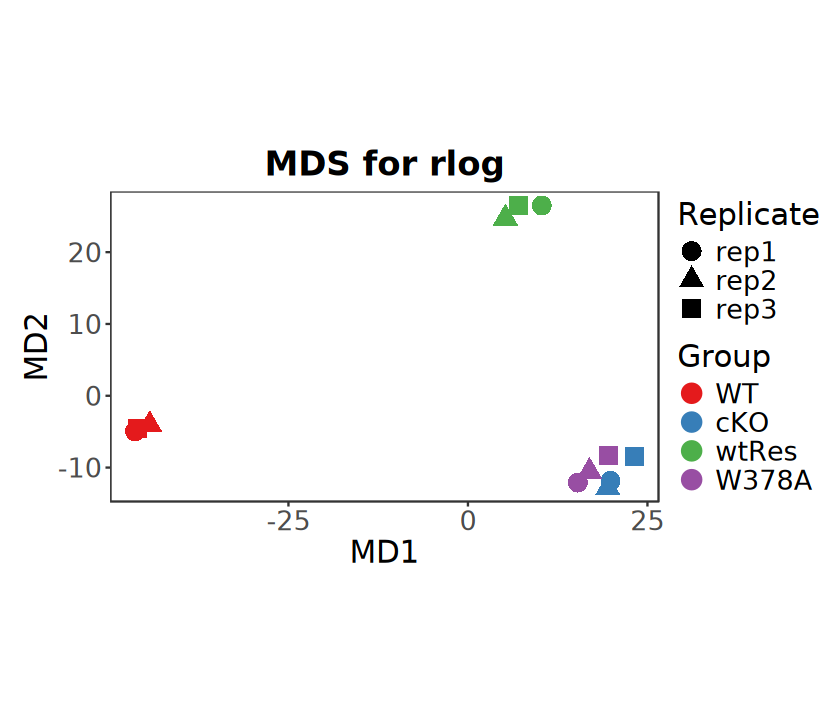

In [52]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [53]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

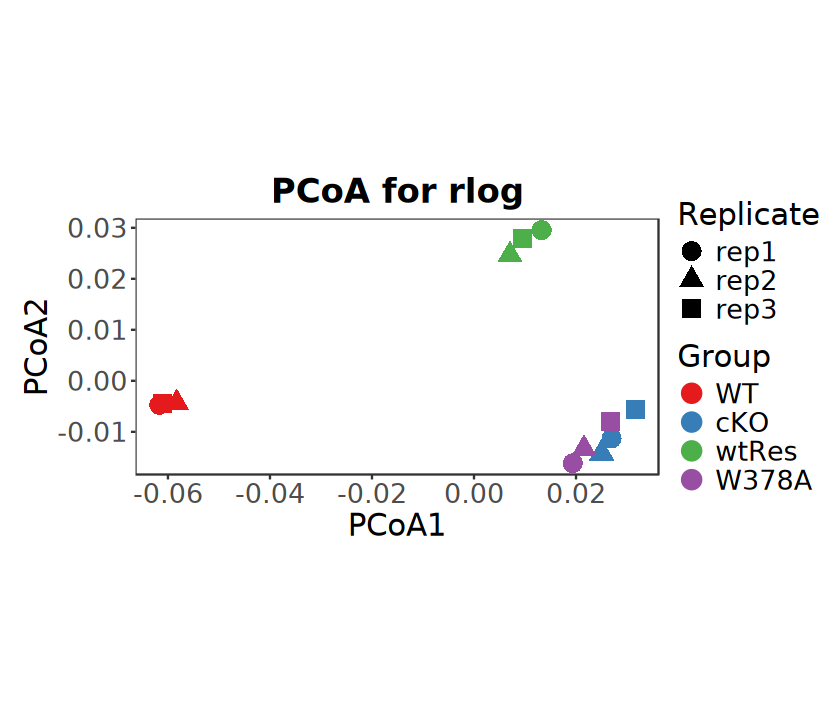

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [55]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [56]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [57]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

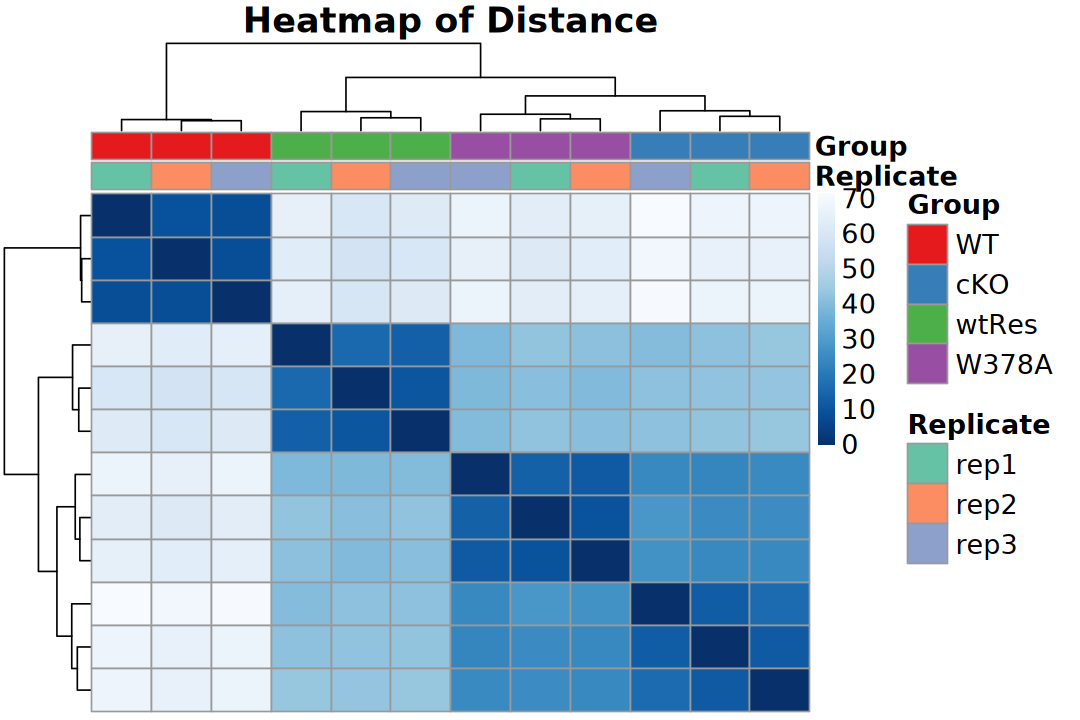

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [59]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

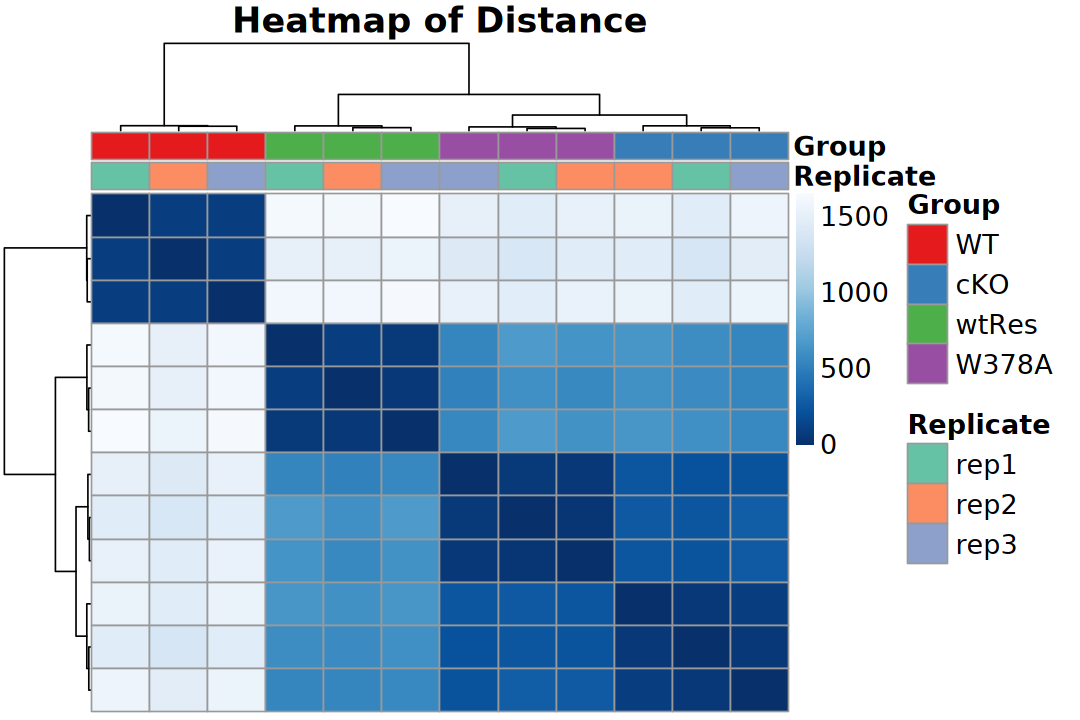

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [61]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

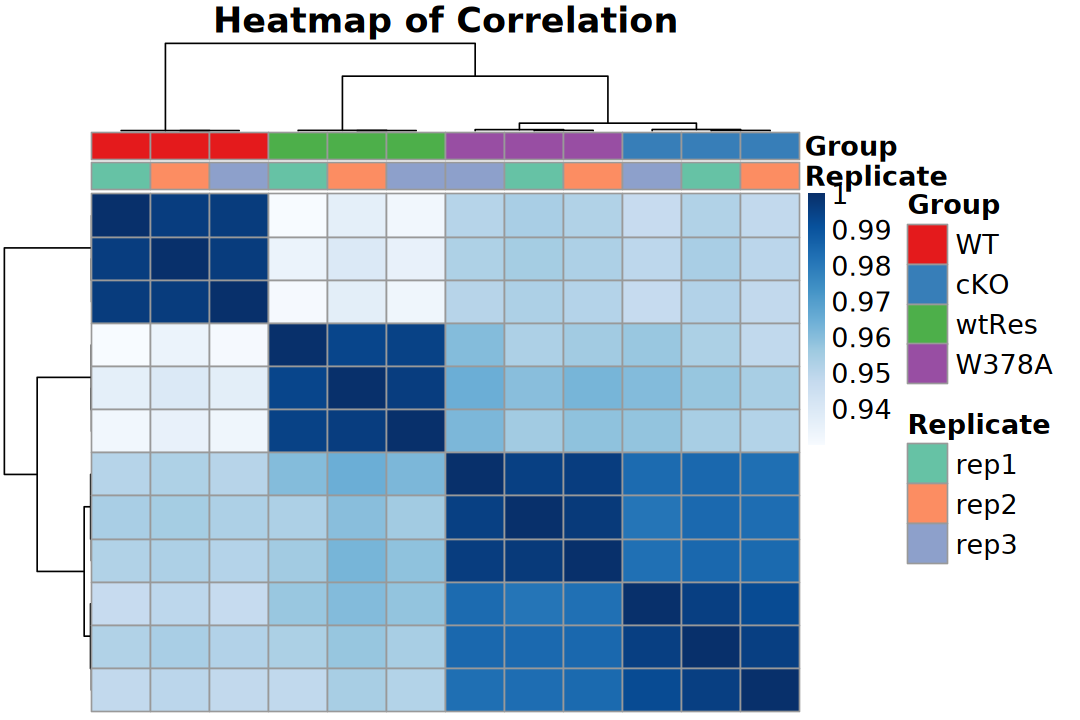

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

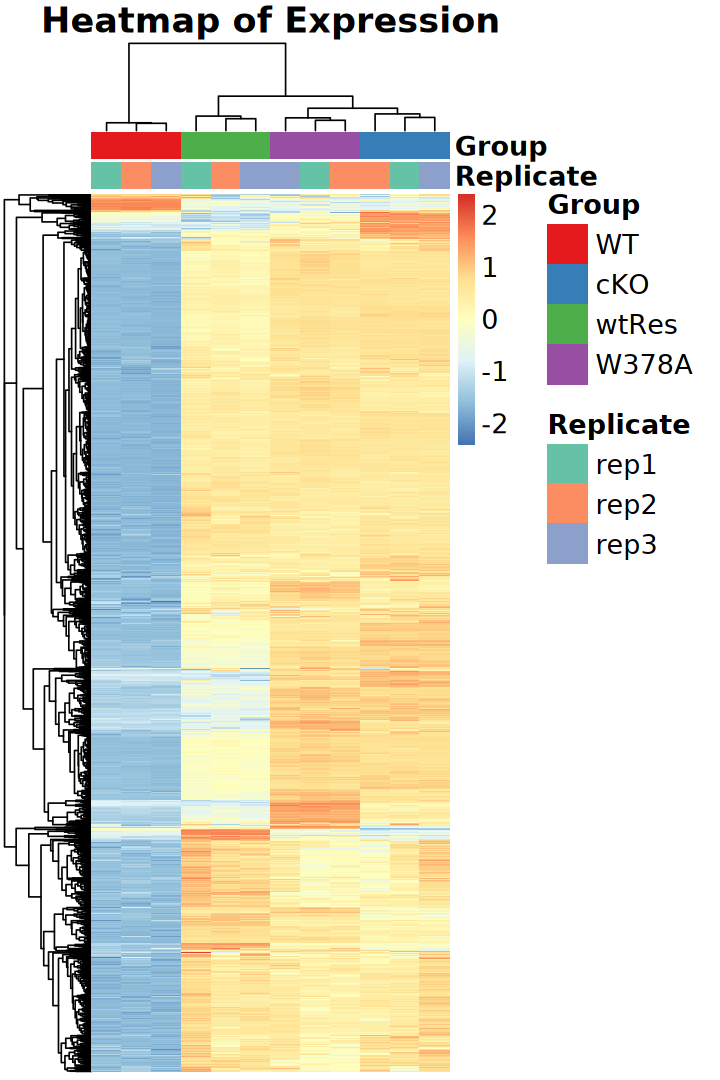

In [63]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [64]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [65]:
design(dds) <- ~ 0 + Group
design(dds)

~0 + Group

In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [67]:
resultsNames(dds)

[1] "GroupWT"    "GroupcKO"   "GroupwtRes" "GroupW378A"

In [68]:
contrast_pairs <- levels(dds$Group) |>
    combn(2, simplify = FALSE)
contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

[1] "cKO_vs_WT"      "wtRes_vs_WT"    "W378A_vs_WT"    "wtRes_vs_cKO"  
[5] "W378A_vs_cKO"   "W378A_vs_wtRes"

### a). Standard

In [69]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Group", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [70]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1658   888 15062
  wtRes_vs_WT     1252   710 15646
  W378A_vs_WT     1629   875 15104
  wtRes_vs_cKO     383   590 16635
  W378A_vs_cKO     109   114 17385
  W378A_vs_wtRes   664   303 16641

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.
>
> Notes:
> - `apeglm` shrunken LFC requires specific coefficients from resultsNames(dds). Re-leveling the reference group is necessary to compute contrasts not inherently present in the initial design matrix.

In [71]:
deseq2_lfc_result_list <- map(contrast_pairs, function(lv) {
    lfcShrink(dds, contrast = c("Group", lv[2], lv[1]), type = "ashr") |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2-lfcShrink",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/

In [72]:
deseq2_lfc_result_df <- bind_rows(deseq2_lfc_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_lfc_result_df$contrast, deseq2_lfc_result_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1253   684 15671
  wtRes_vs_WT      921   581 16106
  W378A_vs_WT     1194   735 15679
  wtRes_vs_cKO     245   403 16960
  W378A_vs_cKO      36    44 17528
  W378A_vs_wtRes   420   179 17009

## 2). edgeR

> Trimmed Mean of M-values (TMM)

In [73]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)

In [74]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[1] "cKO_vs_WT"      "wtRes_vs_WT"    "W378A_vs_WT"    "wtRes_vs_cKO"  
[5] "W378A_vs_cKO"   "W378A_vs_wtRes"

,cKO-WT,wtRes-WT,W378A-WT,wtRes-cKO,W378A-cKO,W378A-wtRes
WT,-1,-1,-1,0,0,0
cKO,1,0,0,-1,-1,0
wtRes,0,1,0,1,0,-1
W378A,0,0,1,0,1,1


### a). Negative binomial GLM framework

In [75]:
dgel <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel, design)

In [76]:
edger_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmLRT(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR-lrt",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [77]:
edger_result_df <- bind_rows(edger_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_result_df$contrast, edger_result_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1689   827 15030
  wtRes_vs_WT     1270   683 15593
  W378A_vs_WT     1640   812 15094
  wtRes_vs_cKO     371   600 16575
  W378A_vs_cKO     114   121 17311
  W378A_vs_wtRes   665   286 16595

### b). Quasi-likelihood pipeline (edgeR v3)

In [78]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [79]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [80]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1685   829 15032
  wtRes_vs_WT     1256   675 15615
  W378A_vs_WT     1636   813 15097
  wtRes_vs_cKO     361   599 16586
  W378A_vs_cKO     105   116 17325
  W378A_vs_wtRes   652   286 16608

In [81]:
comparison_df <- edger_result_df |> 
    dplyr::select(gene_id, contrast, result_lrt = result) |> 
    inner_join(
        edger_qlf_result_df |> 
            dplyr::select(gene_id, contrast, result_qlf = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(LRT = sub_df$result_lrt, QLF = sub_df$result_qlf))
    })


Contrast: cKO_vs_WT 
      QLF
LRT       Up  Down    NS
  Up    1685     0     4
  Down     0   825     2
  NS       0     4 15026

Contrast: wtRes_vs_WT 
      QLF
LRT       Up  Down    NS
  Up    1253     0    17
  Down     0   673    10
  NS       3     2 15588

Contrast: W378A_vs_WT 
      QLF
LRT       Up  Down    NS
  Up    1634     0     6
  Down     0   811     1
  NS       2     2 15090

Contrast: wtRes_vs_cKO 
      QLF
LRT       Up  Down    NS
  Up     360     0    11
  Down     0   597     3
  NS       1     2 16572

Contrast: W378A_vs_cKO 
      QLF
LRT       Up  Down    NS
  Up     105     0     9
  Down     0   115     6
  NS       0     1 17310

Contrast: W378A_vs_wtRes 
      QLF
LRT       Up  Down    NS
  Up     649     0    16
  Down     0   285     1
  NS       3     1 16591


## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [82]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)

In [83]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[1] "cKO_vs_WT"      "wtRes_vs_WT"    "W378A_vs_WT"    "wtRes_vs_cKO"  
[5] "W378A_vs_cKO"   "W378A_vs_wtRes"

,cKO-WT,wtRes-WT,W378A-WT,wtRes-cKO,W378A-cKO,W378A-wtRes
WT,-1,-1,-1,0,0,0
cKO,1,0,0,-1,-1,0
wtRes,0,1,0,1,0,-1
W378A,0,0,1,0,1,1


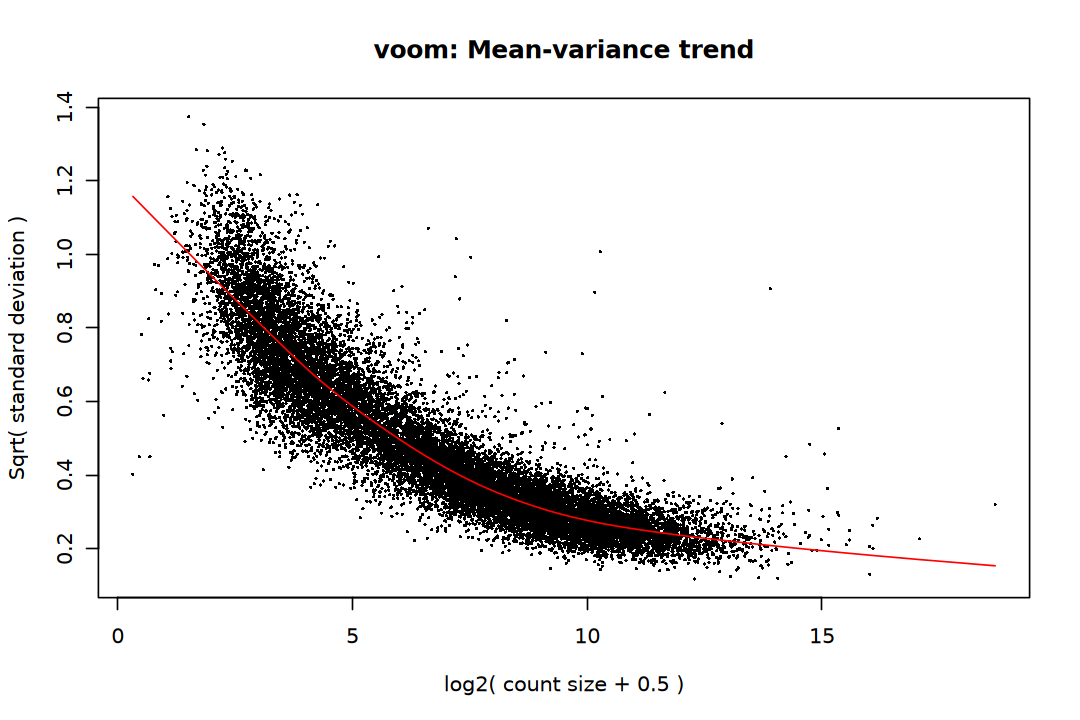

In [84]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [85]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [86]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [87]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1679   846 15021
  wtRes_vs_WT     1260   684 15602
  W378A_vs_WT     1647   827 15072
  wtRes_vs_cKO     381   615 16550
  W378A_vs_cKO     109   120 17317
  W378A_vs_wtRes   661   296 16589

In [88]:
comparison_df <- edger_qlf_result_df |> 
    dplyr::select(gene_id, contrast, result_edger = result) |> 
    inner_join(
        limma_result_df |> 
            dplyr::select(gene_id, contrast, result_limma = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(edgeR = sub_df$result_edger, Limma = sub_df$result_limma))
    })


Contrast: cKO_vs_WT 
      Limma
edgeR     Up  Down    NS
  Up    1622     0    63
  Down     0   807    22
  NS      57    39 14936

Contrast: wtRes_vs_WT 
      Limma
edgeR     Up  Down    NS
  Up    1201     0    55
  Down     0   658    17
  NS      59    26 15530

Contrast: W378A_vs_WT 
      Limma
edgeR     Up  Down    NS
  Up    1572     0    64
  Down     0   806     7
  NS      75    21 15001

Contrast: wtRes_vs_cKO 
      Limma
edgeR     Up  Down    NS
  Up     349     0    12
  Down     0   582    17
  NS      32    33 16521

Contrast: W378A_vs_cKO 
      Limma
edgeR     Up  Down    NS
  Up      93     0    12
  Down     0   108     8
  NS      16    12 17297

Contrast: W378A_vs_wtRes 
      Limma
edgeR     Up  Down    NS
  Up     629     0    23
  Down     0   271    15
  NS      32    25 16551


## DEGs Evaluation

In [89]:
all_results <- bind_rows(
    deseq2_result_df, edger_qlf_result_df, limma_result_df)

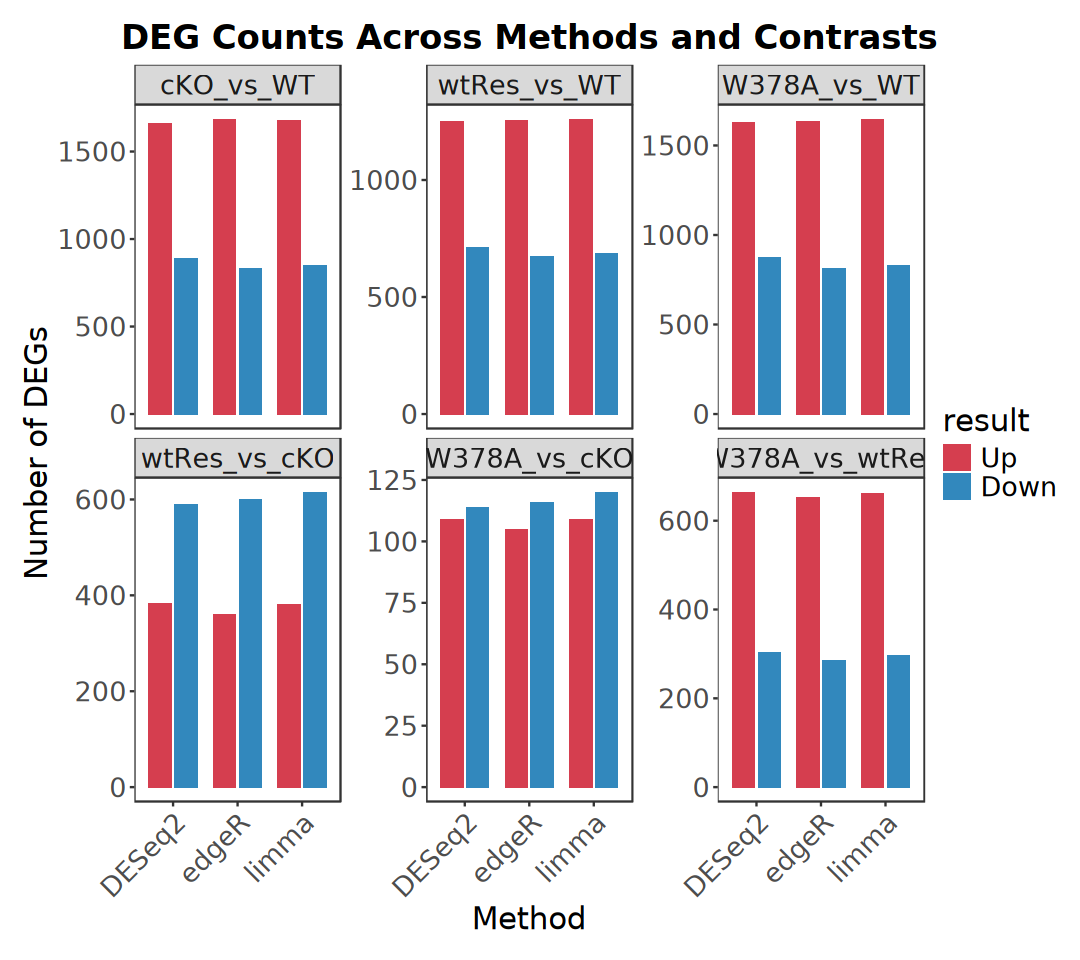

In [90]:
options(repr.plot.width = 9, repr.plot.height = 8)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, ncol = 3, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [91]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [92]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

res_summary <- summarize_software_deg_overlaps("cKO_vs_WT", deg_list)
print(res_summary)

      Group        Combination Counts
1 cKO_vs_WT             DESeq2    102
2 cKO_vs_WT              edgeR      9
3 cKO_vs_WT       DESeq2&edgeR     76
4 cKO_vs_WT              limma     86
5 cKO_vs_WT       DESeq2&limma     10
6 cKO_vs_WT        edgeR&limma     71
7 cKO_vs_WT DESeq2&edgeR&limma   2358


In [93]:
deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

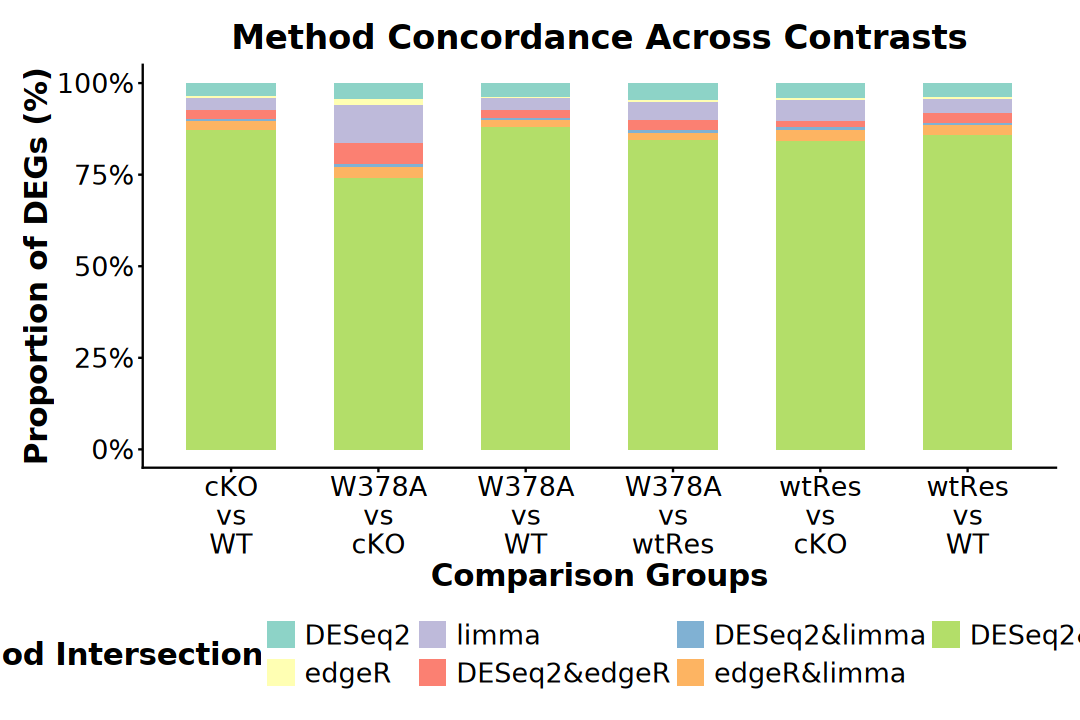

In [94]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "bottom", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18, face = "bold"), 
            axis.text = element_text(size = 16, color = "black"))

## DEGs Visualization

In [95]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1658   888 15062
  wtRes_vs_WT     1252   710 15646
  W378A_vs_WT     1629   875 15104
  wtRes_vs_cKO     383   590 16635
  W378A_vs_cKO     109   114 17385
  W378A_vs_wtRes   664   303 16641

In [96]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### Multi-group Volcano

In [97]:
p1 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

In [98]:
p2 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = logFC, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), width = 0.9,
        height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast),
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_gradientn(
        name = "logFC",
        colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25"), 
        limits = c(-max_logfc, max_logfc)) +
    # scale_color_viridis_c(
    #     name = "logFC", option = "turbo", begin = 0.1, end = 0.9, 
    #     limits = c(-max_logfc, max_logfc)) + 
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

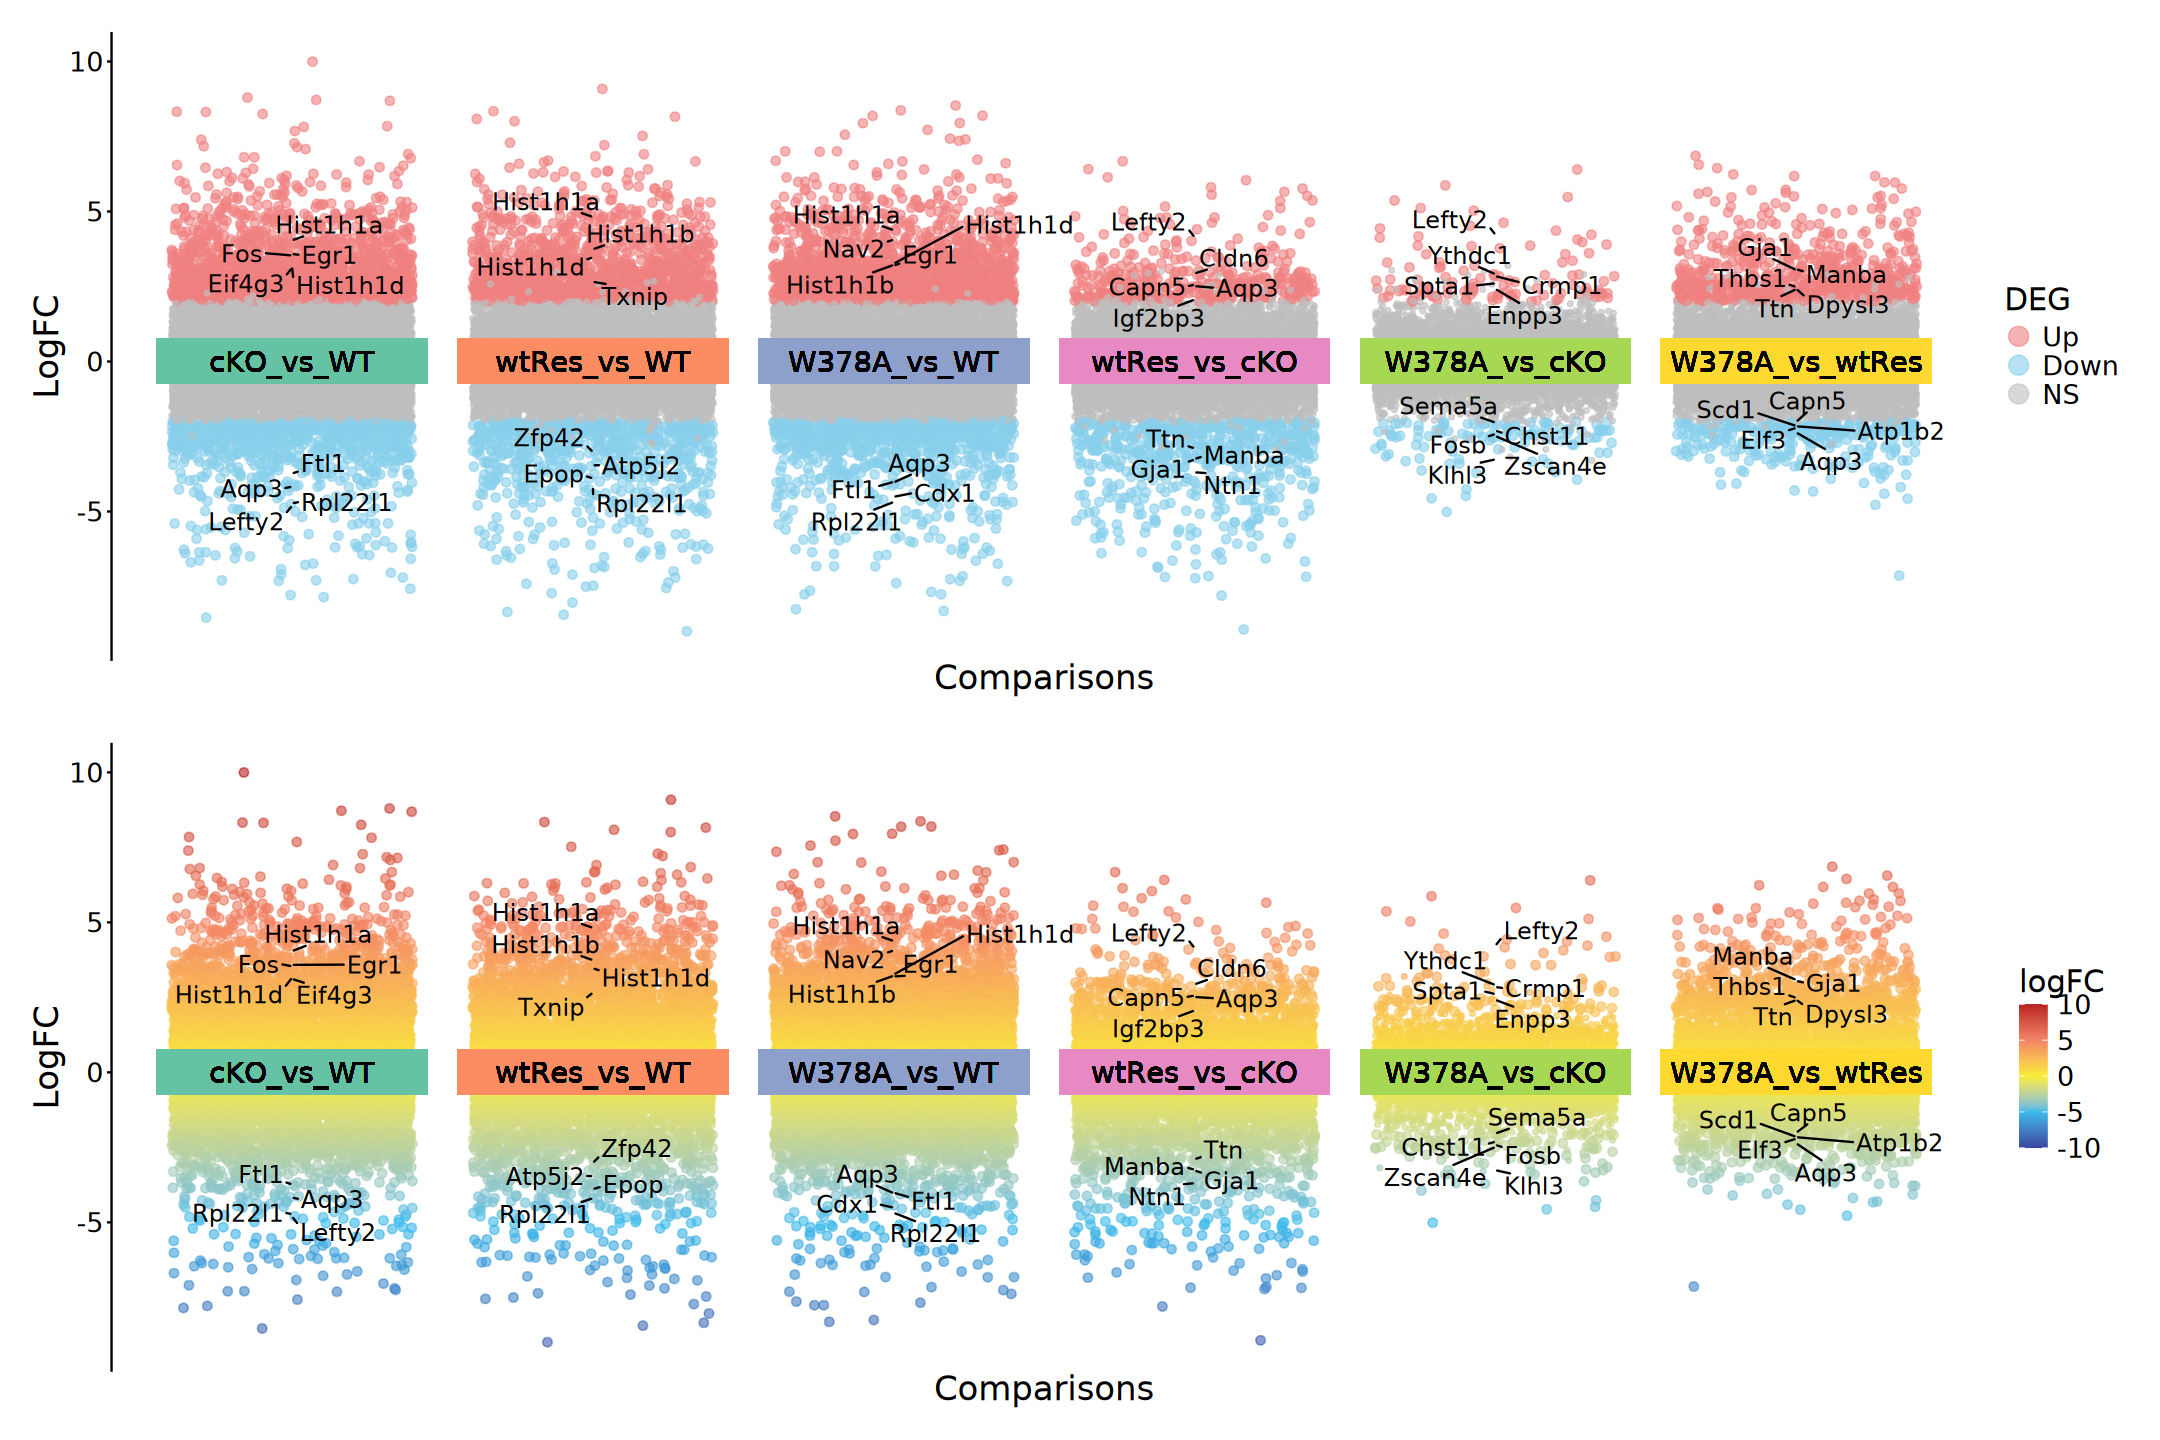

In [99]:
options(repr.plot.width = 18, repr.plot.height = 12)
p1 + p2 + plot_layout(nrow = 2)

### Bubble Matrix Plot

In [100]:
top_genes <- deg_df |> filter(result != "NS") |> 
    group_by(contrast) |> 
    slice_min(order_by = padj, n = 5) |> 
    slice_max(order_by = abs(logFC), n = 5) |> 
    pull(gene_id) |> unique()

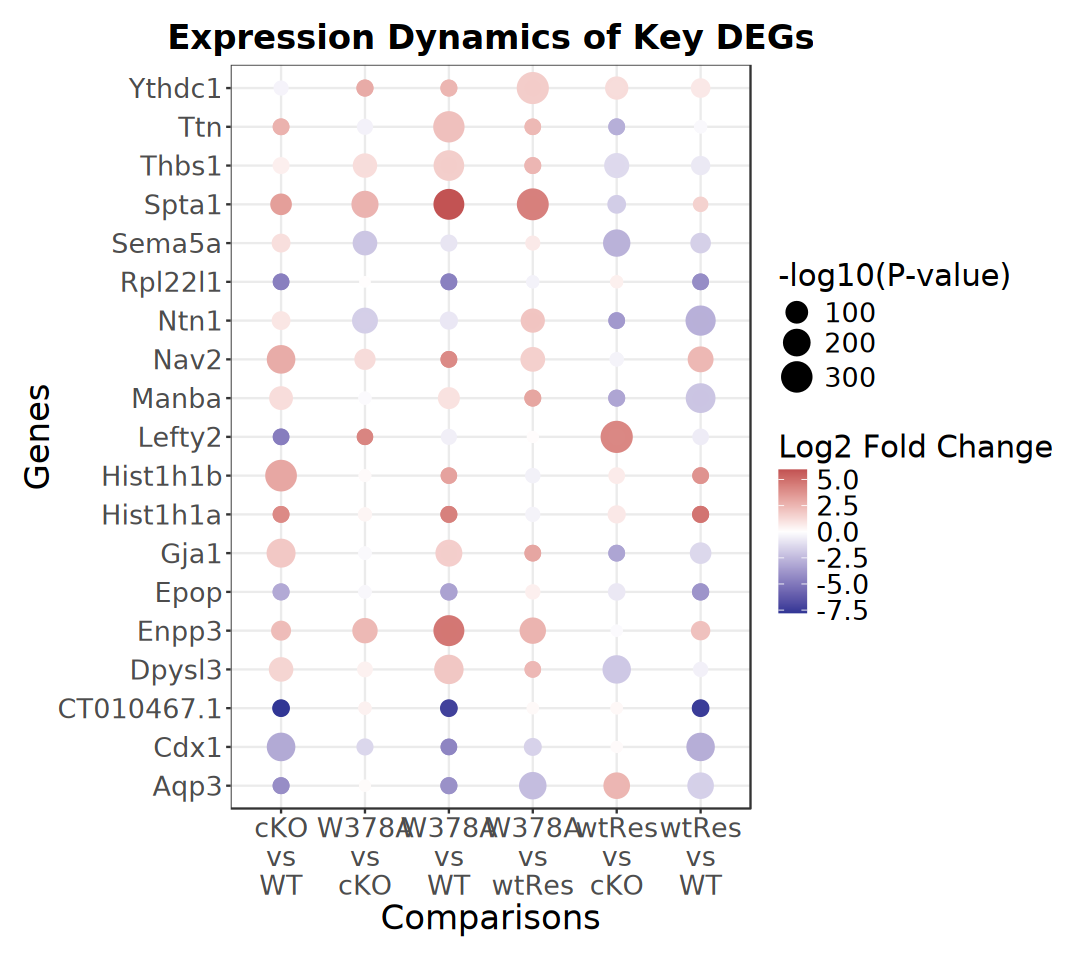

In [101]:
options(repr.plot.width = 9, repr.plot.height = 8)

all_results |> filter(gene_id %in% top_genes) |> 
    mutate(
        Group = str_replace_all(contrast, "_", "\n"),
        neg_log10P = -log10(pvalue)) |> 
    ggplot(aes(x = Group, y = symbol, size = neg_log10P, color = logFC)) +
    geom_point() +
    scale_color_gradient2(
        low = "#313695", mid = "white", high = "#a50026", 
        midpoint = 0) +
    scale_size_continuous(range = c(2, 8)) +
    labs(
        title = "Expression Dynamics of Key DEGs",
        x = "Comparisons", y = "Genes",
        color = "Log2 Fold Change", size = "-log10(P-value)") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16))

### Heatmap

In [102]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [103]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))


ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [104]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels) |>
    append(list(Group = group_colors, Replicate = replicate_colors))

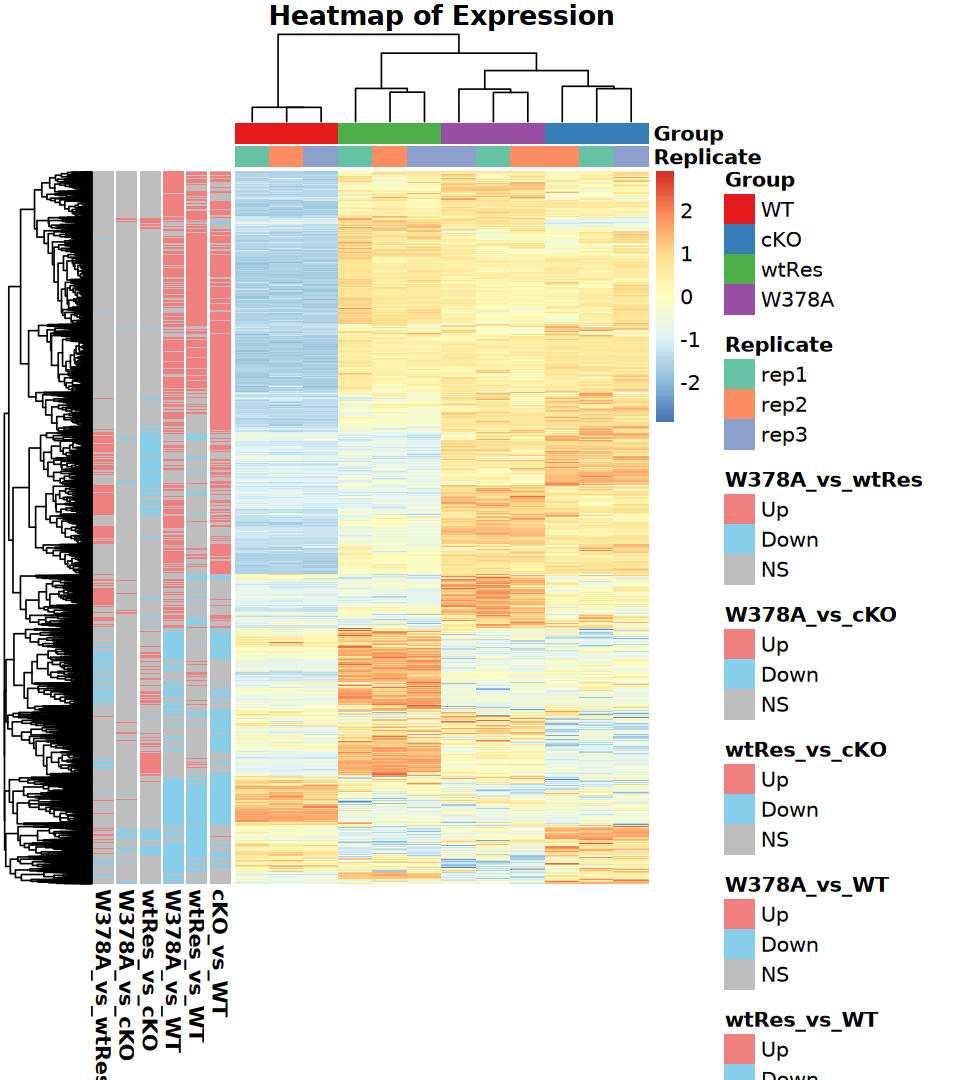

In [105]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [106]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [107]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [108]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [109]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Replicate = replicate_colors))

In [110]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [111]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [112]:
lg_heatmap <- Legend(title = "Expression (z-score)",
                     col_fun = heatmap_col)

lg_group <- Legend(title = "Group", 
                   labels = levels(dds$Group))

lg_replicate <- Legend(title = "Replicate", 
                       labels = levels(dds$Replicate))

lg_deg <- Legend(labels = levels(deg_df$result), title = "DEG", 
                 legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [113]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(name = "Expression", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno, 
            right_annotation = right_anno,
            show_row_names = FALSE, 
            show_column_names = FALSE, 
            use_raster = TRUE)

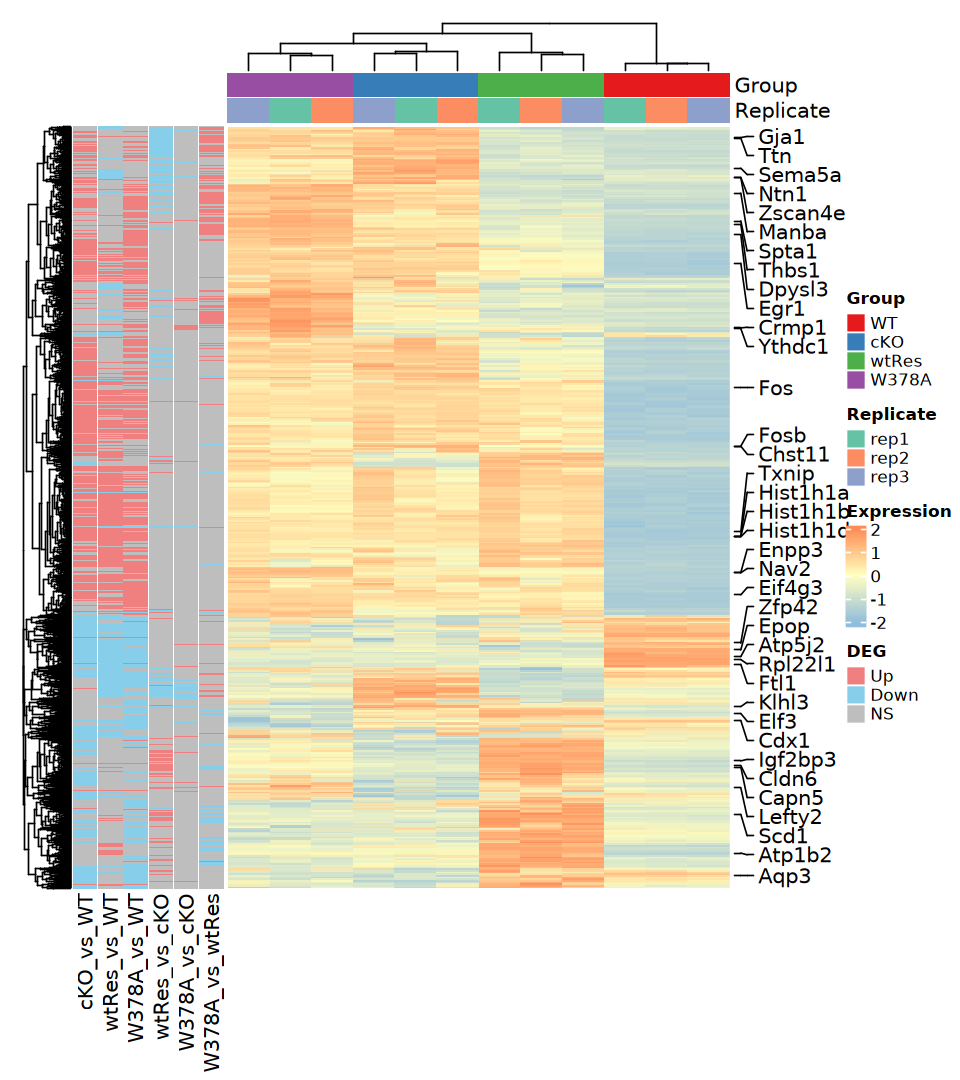

In [114]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(ht + combined_leg, merge_legend = TRUE,
     annotation_legend_list = list(lg_deg), 
     legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
     legend_labels_gp = gpar(fontsize = 10), 
     padding = unit(c(5, 5, 5, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [115]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [116]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [117]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                
                    Up  Down    NS
  cKO_vs_WT       1658   888 15062
  wtRes_vs_WT     1252   710 15646
  W378A_vs_WT     1629   875 15104
  wtRes_vs_cKO     383   590 16635
  W378A_vs_cKO     109   114 17385
  W378A_vs_wtRes   664   303 16641

In [118]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"13.41% of input gene IDs are fail to map..."


In [119]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [120]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [121]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,cKO_vs_WT_Up,BP,GO:0009954,proximal/distal pattern formation,10/677,29/13682,0.34482759,6.968879,7.341348,7.003652e-07,2.874299e-03,2.874299e-03,10
2,wtRes_vs_WT_Up,BP,GO:0050830,defense response to Gram-positive bacterium,11/458,50/13682,0.22000000,6.572140,7.345772,6.019787e-07,2.012415e-03,1.961183e-03,11
3,wtRes_vs_WT_Up,CC,GO:0009897,external side of plasma membrane,28/469,252/13858,0.11111111,3.283108,6.845552,3.220138e-08,1.255854e-05,1.159250e-05,28
4,wtRes_vs_WT_Up,CC,GO:0098552,side of membrane,35/469,482/13858,0.07261411,2.145600,4.791156,1.816371e-05,3.541924e-03,3.269468e-03,35
5,wtRes_vs_WT_Up,CC,GO:0001534,radial spoke,5/469,12/13858,0.41666667,12.311656,7.336714,2.826505e-05,3.674457e-03,3.391807e-03,5
6,wtRes_vs_WT_Up,MF,GO:0004888,transmembrane signaling receptor activity,37/449,394/13585,0.09390863,2.841311,6.857122,1.015565e-08,6.001988e-06,5.462669e-06,37


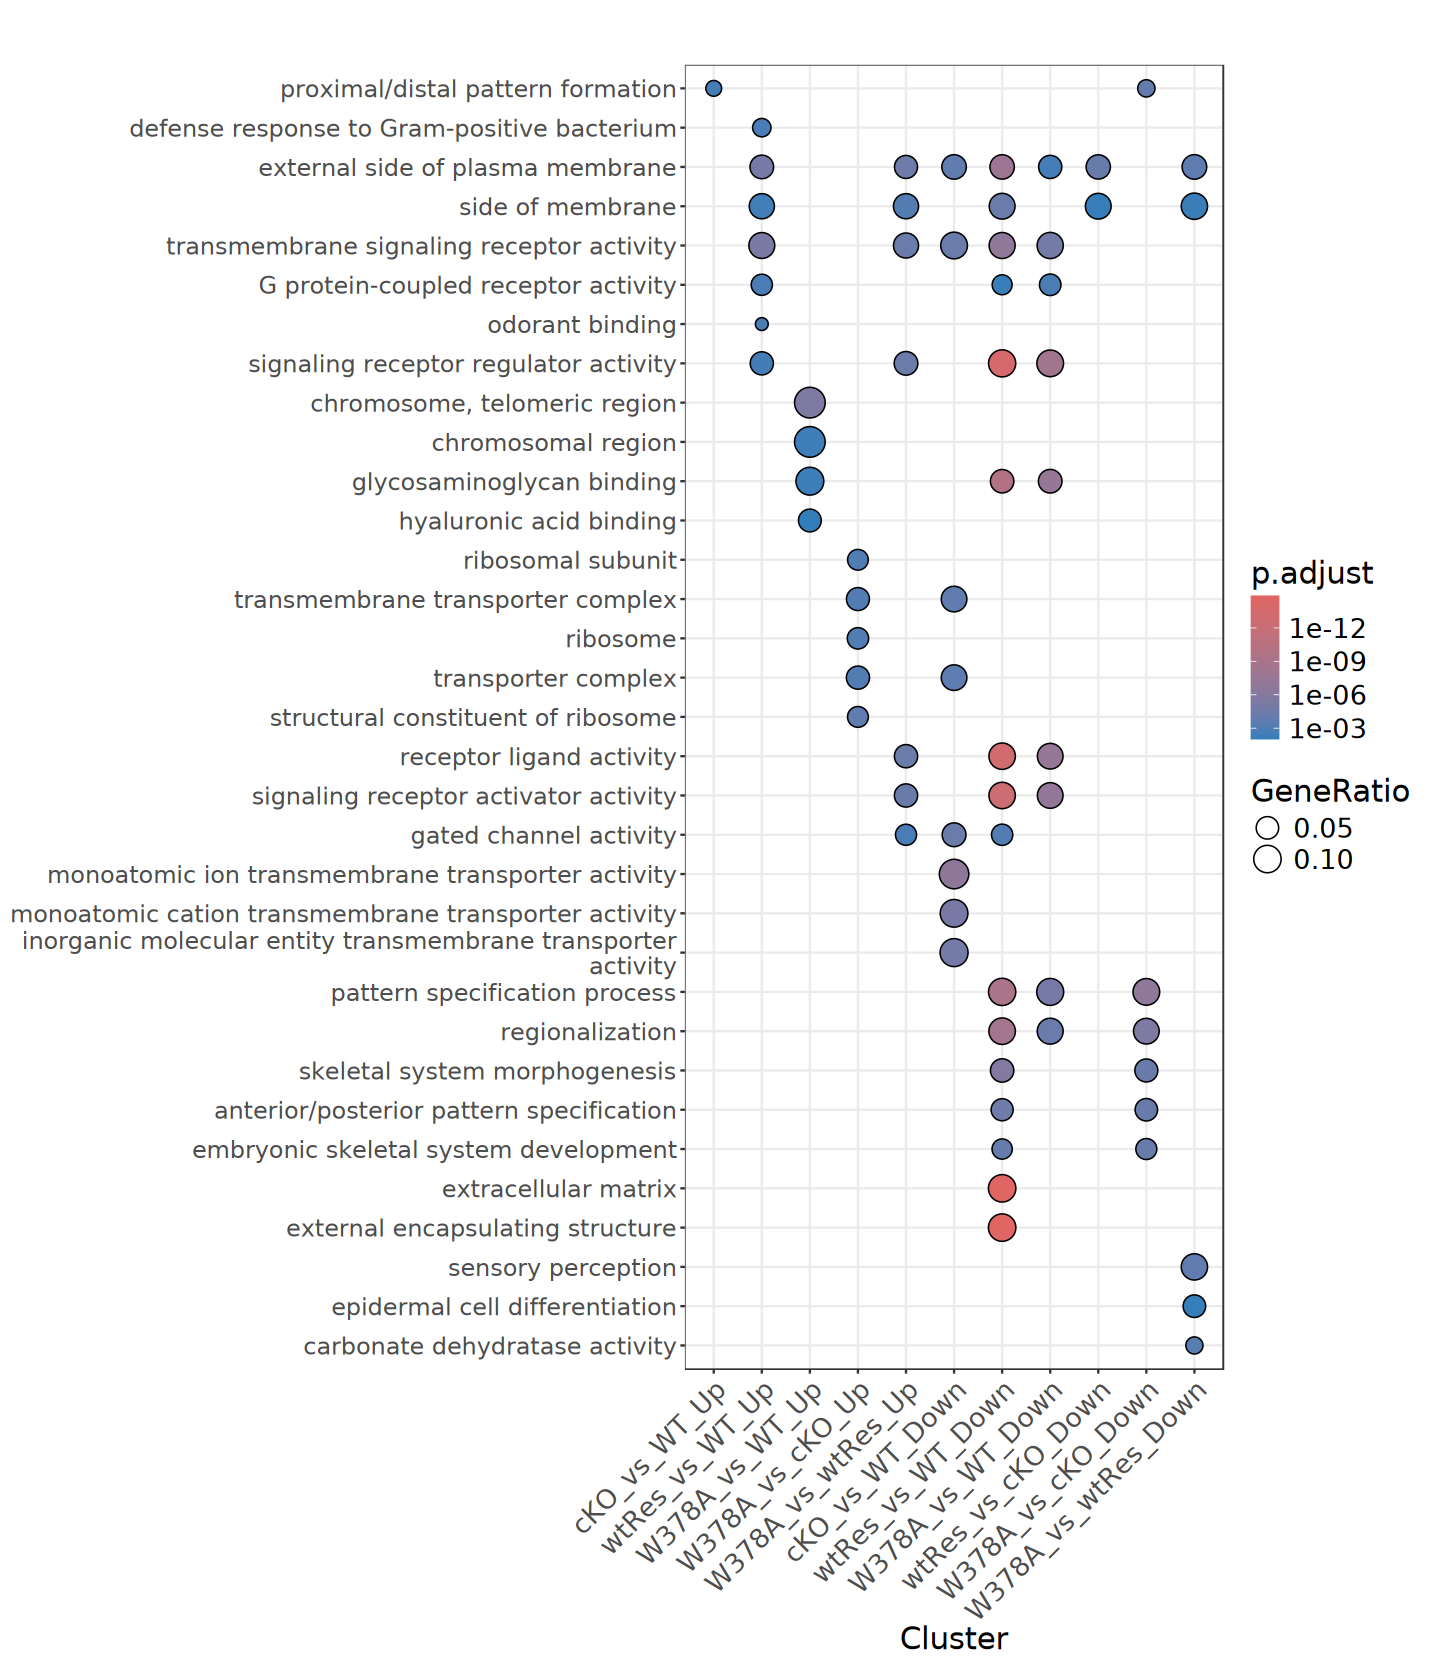

In [122]:
options(repr.plot.width = 12, repr.plot.height = 14)

dotplot(ego_compare, showCategory = 5, label_format = 60) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [123]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [124]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [125]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,cKO_vs_WT_Up,Human Diseases,Immune disease,mmu05322,Systemic lupus erythematosus,20/333,90/6227,0.2222222,4.155489,7.166902,3.416924e-08,9.977417e-06,9.351580e-06,20
2,cKO_vs_WT_Up,Human Diseases,Substance dependence,mmu05034,Alcoholism,21/333,149/6227,0.1409396,2.635528,4.802777,3.753896e-05,5.480688e-03,5.136910e-03,21
3,wtRes_vs_WT_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04080,Neuroactive ligand-receptor interaction,18/209,123/6227,0.1463415,4.360135,7.013805,1.097227e-07,2.841818e-05,2.667994e-05,18
4,wtRes_vs_WT_Up,Organismal Systems,Immune system,mmu04610,Complement and coagulation cascades,8/209,41/6227,0.1951220,5.813514,5.762366,5.177627e-05,6.705027e-03,6.294904e-03,8
5,W378A_vs_cKO_Up,Human Diseases,Immune disease,mmu05322,Systemic lupus erythematosus,23/340,90/6227,0.2555556,4.680425,8.451585,2.379905e-10,7.092117e-08,6.563528e-08,23
6,W378A_vs_cKO_Up,Metabolism,Energy metabolism,mmu00190,Oxidative phosphorylation,22/340,126/6227,0.1746032,3.197806,5.989231,9.326311e-07,1.389620e-04,1.286049e-04,22


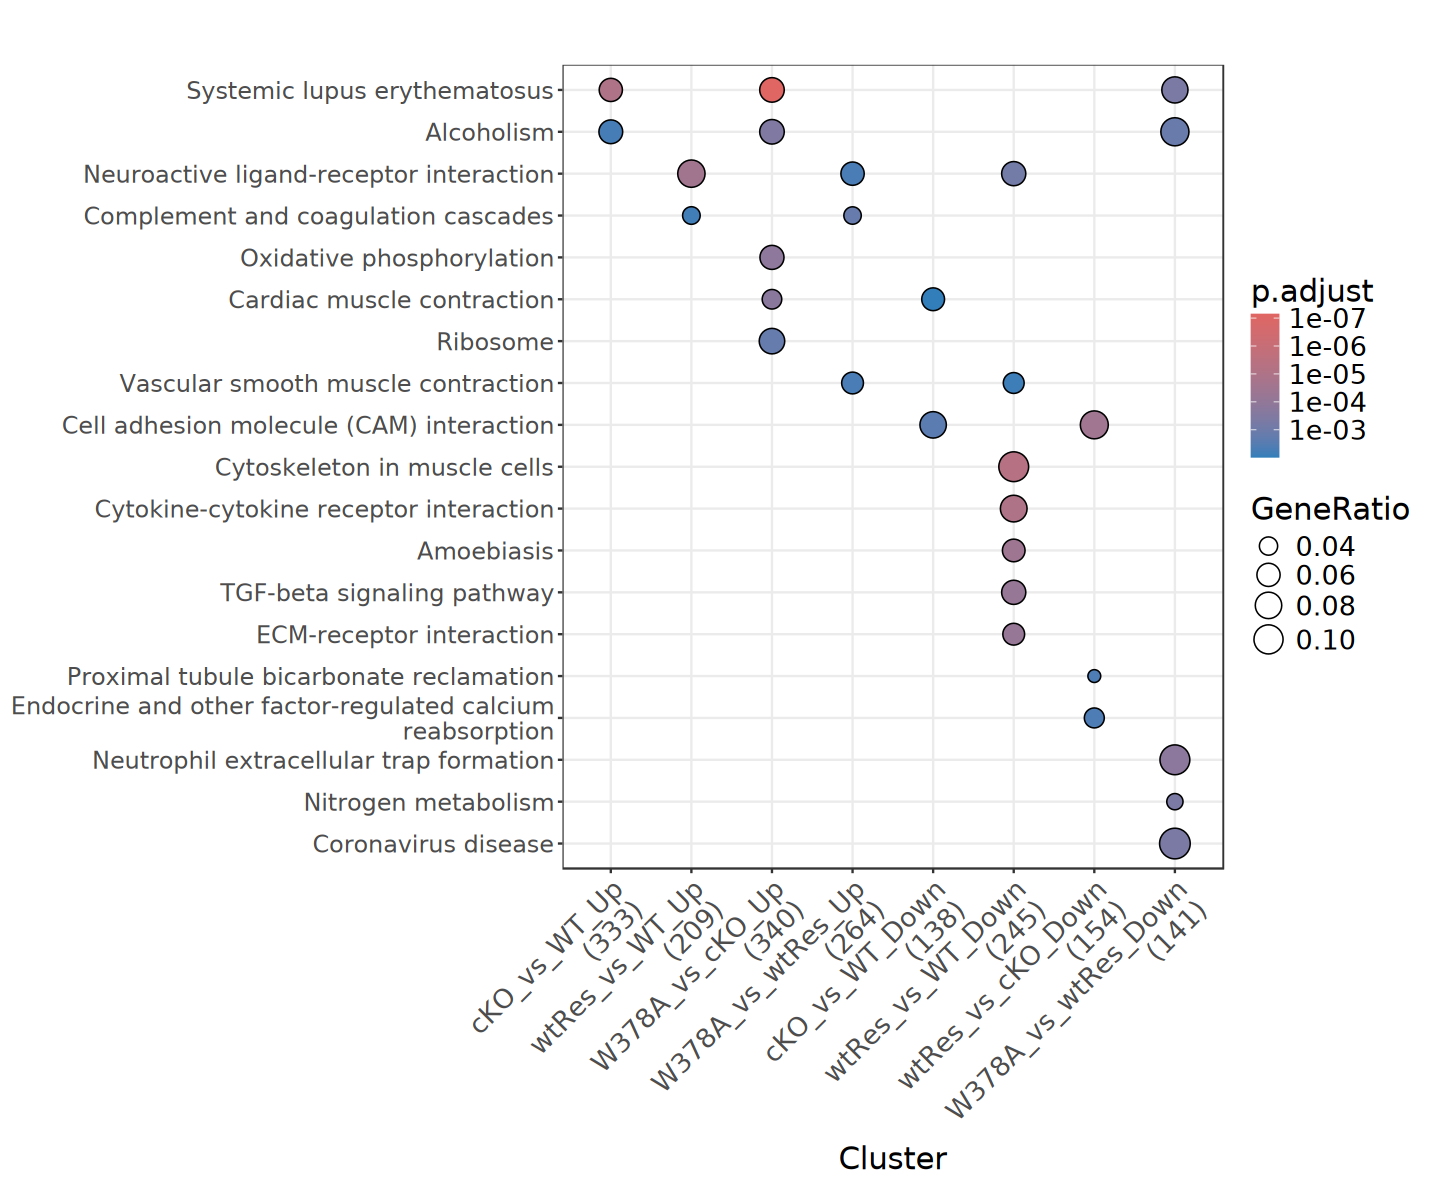

In [126]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)